In [70]:
from pathlib import Path
import sys, pickle, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from IPython.display import display

# The example notebook uses ../helpers.py; also allow helpers.py next to this notebook.
for directory in (Path.cwd(), Path.cwd().parent):
    if (directory / 'helpers.py').is_file():
        sys.path.insert(0, str(directory))
        break
try:
    import helpers as hp
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError('Place helpers.py next to this notebook or in its parent directory.') from exc

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 250, 'axes.grid': True, 'grid.alpha': 0.2})
print(f'Using helpers from: {Path(hp.__file__).resolve()}')

Using helpers from: /home/vinicius/Documents/backup_Unf/UnfoldingBSMttbar/Plots/helpers.py


In [71]:
# === Dataset and tested hypothesis ===
WORKSPACE_FILE = 'pT_mass_scan_13_6TeV_hists.pkl'  # saved workspace
OBSERVABLE = 'pT'                                  # use the workspace observable
FAKE_DATA_KEY = 'Scalar_1500'                     # Scalar_1500, VLF_1500, Zprime_3000, ...
FAKE_SCALE = None                                 # None -> helpers.DEFAULT_FAKE_SCALES, 
TEST_MODEL = 'Zprime'                                # Scalar, VLF, Zprime, Zprime_20pc
TEST_MASSES = [ 2500, 3000]                  # masses 

# === Statistic, luminosity, bin range, and SYSTEMATICS ===
LUMINOSITY_FB = 500.0
SYSTEMATICS = [0.0, 0.01]                   # fractions: 0%, 2%, 5%. Use [0.02] for one case
DETAIL_SYSTEMATIC = 0.01                          # systematic shown in the detailed plots
PLOT_ALL_SYSTEMATICS = False                      # True -> detailed plots for each entry
FIT_RANGE = (000, 4600)                           # endpoints must match stored bin edges
PLOT_RANGE = None                                 # None -> fit range; or wider bin-aligned range
STATISTIC = 'poisson'                             # 'poisson' (profiled) or 'pearson' (approximate)

# === Direct comparison: no systematics vs one chosen systematic ===
COMPARE_TO_NO_SYSTEMATICS = True                  # automatically include epsilon=0 if missing
COMPARISON_SYSTEMATIC = 0.01                      # compare epsilon=0 against this entry
COMPARISON_LAYOUT = 'side_by_side'                # 'side_by_side' or 'stacked'
COMPARISON_MATCH_YLIM = True                      # use the same y range in both panels

# === Fit boundaries as defined by the original helper ===
SCALE_BOUNDS = {'Scalar': (0.0, 10.1), 'VLF': (0.0, 7.0),
                'Zprime': (-100.0, 100.0), 'Zprime_20pc': (-100.0, 100.0)}
COARSE_SCAN_POINTS = 601                          # scan local minima before bounded refinement

# === Plotting and exports ===
YIELD_Y_SCALE = 'log'                             # 'log' or 'linear'
SHOW_INDIVIDUAL_PANELS = True                     # one bin-contribution plot per mass
EXPORT_RESULTS = True
OUTPUT_DIR = Path('binwise_z2_systematics_outputs')

In [72]:
def resolve_workspace_path(filename):
    path = Path(filename).expanduser()
    candidates = [path] if path.is_absolute() else [Path.cwd() / path, Path.cwd().parent / path]
    for candidate in candidates:
        if candidate.is_file():
            return candidate.resolve()
    raise FileNotFoundError(f'Workspace not found: {filename}. Searched: {[str(p) for p in candidates]}')


def load_workspace(filename, observable):
    path = resolve_workspace_path(filename)
    with path.open('rb') as file:
        workspace = pickle.load(file)  # Use only your own/trusted workspace pickle.
    required = ('bins', 'SM', 'FakeData', 'Models')
    missing = [key for key in required if key not in workspace]
    if missing:
        raise KeyError(f'Workspace is missing keys: {missing}')
    stored = workspace.get('observable')
    if stored is not None and str(stored) != str(observable):
        raise ValueError(f'Workspace observable={stored!r}, requested={observable!r}')
    bins = np.asarray(workspace['bins'], dtype=float)
    if bins.ndim != 1 or len(bins) < 2 or not np.all(np.isfinite(bins)) or np.any(np.diff(bins) <= 0):
        raise ValueError('Workspace bins must be finite, 1D, and strictly increasing.')
    sm = checked_hist('SM', workspace['SM'], len(bins) - 1)
    if np.any(sm < 0):
        raise ValueError('SM histogram contains negative cross sections.')
    return path, workspace, bins, sm


def checked_hist(name, hist, count):
    arr = np.asarray(hist, dtype=float)
    if arr.shape != (count,) or not np.all(np.isfinite(arr)):
        raise ValueError(f'{name}: expected {count} finite bins; got {arr.shape}.')
    return arr.copy()


def window_mask(edges, limits, name='FIT_RANGE'):
    """Only full stored bins; explicit alignment prevents silently including partial bins."""
    lo, hi = map(float, limits)
    if lo >= hi:
        raise ValueError(f'{name}: lower edge must be smaller than upper edge.')
    indices = []
    for value in (lo, hi):
        matches = np.flatnonzero(np.isclose(edges, value, rtol=0.0, atol=1e-7))
        if len(matches) != 1:
            raise ValueError(f'{name} endpoint {value:g} is not a stored bin edge. '
                             f'Workspace spans [{edges[0]:g}, {edges[-1]:g}] GeV; '
                             f'use values from the stored bins.')
        indices.append(int(matches[0]))
    if indices[1] <= indices[0]:
        raise ValueError(f'{name} must include at least one complete bin.')
    result = np.zeros(len(edges) - 1, dtype=bool)
    result[indices[0]:indices[1]] = True
    return result


def grid_masses(workspace, model):
    if model not in workspace['Models']:
        raise KeyError(f'Unknown test model {model!r}. Available models: {list(workspace["Models"])}')
    return sorted(float(m) for m in workspace['Models'][model])


def exact_mass_key(grid, mass, model):
    matches = [key for key in grid if np.isclose(float(key), mass, rtol=0.0, atol=1e-7)]
    if len(matches) != 1:
        values = sorted(float(k) for k in grid)
        raise KeyError(f'Mass {mass:g} GeV is not uniquely available for {model}. '
                       f'Available grid masses: {values}')
    return matches[0]


def get_fake_signal(workspace, fake_key, fake_scale, nbins):
    if fake_key not in workspace['FakeData']:
        raise KeyError(f'{fake_key!r} not found. Available: {list(workspace["FakeData"])}')
    entry = workspace['FakeData'][fake_key]
    pure = checked_hist(f'FakeData[{fake_key}].pure', entry['pure'], nbins)
    if fake_key.startswith('Zprime'):
        interference = checked_hist(f'FakeData[{fake_key}].int', entry['int'], nbins)
        return fake_scale**2 * pure + fake_scale * interference
    return fake_scale**2 * pure


def get_test_templates(workspace, model, mass, nbins):
    grid = workspace['Models'][model]
    key = exact_mass_key(grid, mass, model)
    pure = checked_hist(f'{model}[{mass:g}]', grid[key], nbins)
    interference = None
    if model.startswith('Zprime'):
        int_key = f'{model}_int'
        if int_key not in workspace['Models']:
            raise KeyError(f'Missing interference model key {int_key!r}')
        int_grid = workspace['Models'][int_key]
        i_key = exact_mass_key(int_grid, mass, int_key)
        interference = checked_hist(f'{int_key}[{mass:g}]', int_grid[i_key], nbins)
    return pure, interference


def signal_at_scale(pure, interference, scale):
    """Scalar/VLF: k²*pure; Zprime: k²*pure + k*interference."""
    return scale**2 * pure if interference is None else scale**2 * pure + scale * interference


def bin_statistic(n_obs, n_test, n_sm, frac_syst, statistic):
    """Return bin contributions q_i, nuisance parameters and profiled expectations."""
    if np.any(~np.isfinite(n_test)) or np.any(n_test <= 0):
        raise ValueError('Model expectation must be finite and strictly positive in fit bins.')
    if np.any(~np.isfinite(n_obs)) or np.any(n_obs < 0):
        raise ValueError('Asimov count must be finite and nonnegative in fit bins.')
    if statistic == 'poisson':
        _, theta, profile = hp._profiled_poisson_deviance(
            n_obs, n_test, frac_syst=frac_syst, syst_reference=n_sm)
        q_bins = hp._poisson_deviance(n_obs, profile) + theta**2
        # Roundoff in a tiny deviance can occasionally produce a value slightly below zero.
        if np.any(q_bins < -1e-8):
            raise ArithmeticError('Unexpected negative Poisson deviance.')
        q_bins = np.maximum(q_bins, 0.0)
        return q_bins, theta, profile
    if statistic == 'pearson':
        denominator = n_test + (frac_syst * n_sm)**2
        q_bins = (n_obs - n_test)**2 / denominator
        return q_bins, np.zeros_like(n_test), n_test.copy()
    raise ValueError("STATISTIC must be 'poisson' or 'pearson'.")


def fit_fixed_mass(mass, pure, interference, n_sm, n_fake_total,
                   mask, yield_factor, scale_bounds, frac_syst, statistic, n_scan):
    """Profile k at ONE mass; search all visible local minima incl. signed Z' branches."""
    lo, hi = map(float, scale_bounds)
    if not np.isfinite([lo, hi]).all() or lo >= hi or n_scan < 5:
        raise ValueError('Invalid coupling search bounds or COARSE_SCAN_POINTS.')
    obs = n_fake_total[mask]
    sm_fit = n_sm[mask]
    pure_fit = pure[mask]
    int_fit = None if interference is None else interference[mask]

    def objective(k):
        test = sm_fit + yield_factor * signal_at_scale(pure_fit, int_fit, float(k))
        if np.any(~np.isfinite(test)) or np.any(test <= 0):
            return np.inf
        try:
            q_i, _, _ = bin_statistic(obs, test, sm_fit, frac_syst, statistic)
            return float(np.sum(q_i) / yield_factor)  # same positive normalization as helpers.py
        except (ValueError, ArithmeticError, FloatingPointError):
            return np.inf

    ks = np.linspace(lo, hi, int(n_scan))
    qs = np.array([objective(k) for k in ks])
    finite = np.flatnonzero(np.isfinite(qs))
    if not len(finite):
        raise RuntimeError(f'No physical fit candidate for mass {mass:g} GeV.')
    candidates = {int(finite[np.argmin(qs[finite])])}
    for i in finite:
        if qs[i] <= (qs[i-1] if i else np.inf) and qs[i] <= (qs[i+1] if i+1 < len(ks) else np.inf):
            candidates.add(int(i))
    # Explicit zero matters for signed Z' interference branches.
    special_ks = [0.0] if lo <= 0 <= hi else []
    choices = [(float(ks[i]), float(qs[i])) for i in candidates]
    choices += [(k, objective(k)) for k in special_ks]
    for i in candidates:
        if 0 < i < len(ks) - 1 and np.isfinite(qs[i-1]) and np.isfinite(qs[i+1]):
            fit = minimize_scalar(objective, bounds=(ks[i-1], ks[i+1]), method='bounded',
                                  options={'xatol': 1e-10, 'maxiter': 500})
            if fit.success and np.isfinite(fit.fun):
                choices.append((float(fit.x), float(fit.fun)))
    k_best, _ = min(choices, key=lambda row: row[1])
    signal = yield_factor * signal_at_scale(pure, interference, k_best)
    n_test = n_sm + signal
    if np.any(n_test[mask] <= 0):
        raise ArithmeticError('Fitted model expectation is nonpositive in fit bins.')
    q_fit, theta_fit, mu_fit = bin_statistic(obs, n_test[mask], sm_fit, frac_syst, statistic)
    q_total = float(np.sum(q_fit))
    nbin = len(n_sm)
    q_all = np.full(nbin, np.nan)
    theta_all = np.full(nbin, np.nan)
    mu_all = np.full(nbin, np.nan)
    q_all[mask], theta_all[mask], mu_all[mask] = q_fit, theta_fit, mu_fit
    return {'mass': float(mass), 'scale': float(k_best), 'Z2': q_total,
            'Z': np.sqrt(max(q_total, 0.0)), 'signal': signal, 'n_test': n_test,
            'q_bins': q_all, 'theta': theta_all, 'mu_profile': mu_all}

In [73]:
workspace_path, ws, bins, h_sm = load_workspace(WORKSPACE_FILE, OBSERVABLE)
if not np.isfinite(LUMINOSITY_FB) or LUMINOSITY_FB <= 0:
    raise ValueError('LUMINOSITY_FB must be finite and positive.')
if STATISTIC not in ('poisson', 'pearson'):
    raise ValueError("STATISTIC must be 'poisson' or 'pearson'.")
if TEST_MODEL not in SCALE_BOUNDS:
    raise KeyError(f'TEST_MODEL must be one of {list(SCALE_BOUNDS)}')
if not SYSTEMATICS:
    raise ValueError('SYSTEMATICS must contain at least one fractional uncertainty.')
systematics = [float(eps) for eps in SYSTEMATICS]
if not all(np.isfinite(eps) and eps >= 0 for eps in systematics):
    raise ValueError('SYSTEMATICS entries must be nonnegative finite fractions.')

comparison_systematic = float(COMPARISON_SYSTEMATIC)
if not np.isfinite(comparison_systematic) or comparison_systematic < 0:
    raise ValueError('COMPARISON_SYSTEMATIC must be a nonnegative finite fraction.')
if COMPARISON_LAYOUT not in ('side_by_side', 'stacked'):
    raise ValueError("COMPARISON_LAYOUT must be 'side_by_side' or 'stacked'.")

# Ensure the requested systematics are present when direct comparison is enabled.
if COMPARE_TO_NO_SYSTEMATICS:
    if not any(np.isclose(0.0, eps, rtol=0.0, atol=1e-12) for eps in systematics):
        systematics = [0.0] + systematics
    if not any(np.isclose(comparison_systematic, eps, rtol=0.0, atol=1e-12) for eps in systematics):
        systematics.append(comparison_systematic)

# Deduplicate while preserving order.
deduped = []
for eps in systematics:
    if not any(np.isclose(eps, other, rtol=0.0, atol=1e-12) for other in deduped):
        deduped.append(float(eps))
systematics = deduped

if not any(np.isclose(float(DETAIL_SYSTEMATIC), eps, rtol=0, atol=1e-12) for eps in systematics):
    raise ValueError('DETAIL_SYSTEMATIC must be one of the SYSTEMATICS values (after any automatic additions).')
selected_systematic = next(eps for eps in systematics if np.isclose(eps, DETAIL_SYSTEMATIC, rtol=0, atol=1e-12))
comparison_systematic = next(eps for eps in systematics if np.isclose(eps, comparison_systematic, rtol=0, atol=1e-12))

fit_mask = window_mask(bins, FIT_RANGE, 'FIT_RANGE')
plot_mask = window_mask(bins, PLOT_RANGE if PLOT_RANGE is not None else FIT_RANGE, 'PLOT_RANGE')
scan_masses = grid_masses(ws, TEST_MODEL)
print(f'Workspace: {workspace_path}')
print(f'Observable: {OBSERVABLE}; bins: {len(bins)-1}, stored range [{bins[0]:g}, {bins[-1]:g}] GeV')
print(f'Fake data available: {list(ws["FakeData"])}')
print(f'{TEST_MODEL} available mass grid ({len(scan_masses)} points): {scan_masses}')
print(f'Fit interval: [{FIT_RANGE[0]:g}, {FIT_RANGE[1]:g}] GeV ({sum(fit_mask)} complete bins)')
print('Systematics:', ', '.join(f'{100*eps:g}%' for eps in systematics), '(independent SM background nuisances)')
if COMPARE_TO_NO_SYSTEMATICS:
    print(f'Direct comparison enabled: ε=0% vs ε={100*comparison_systematic:g}% | layout={COMPARISON_LAYOUT}')

Workspace: /home/vinicius/Documents/backup_Unf/UnfoldingBSMttbar/Plots/pT_mass_scan_13_6TeV_hists.pkl
Observable: pT; bins: 49, stored range [0, 4900] GeV
Fake data available: ['Zprime_3000', 'Scalar_1500', 'VLF_1500']
Zprime available mass grid (16 points): [2000.0, 2100.0, 2200.0, 2300.0, 2400.0, 2500.0, 2600.0, 2700.0, 2800.0, 2900.0, 3000.0, 3100.0, 3200.0, 3300.0, 3400.0, 3500.0]
Fit interval: [0, 4600] GeV (46 complete bins)
Systematics: 0%, 1% (independent SM background nuisances)
Direct comparison enabled: ε=0% vs ε=1% | layout=side_by_side


In [74]:
if FAKE_SCALE is None:
    if FAKE_DATA_KEY not in hp.DEFAULT_FAKE_SCALES:
        raise KeyError(f'No default scale for {FAKE_DATA_KEY!r}. Set FAKE_SCALE explicitly.')
    fake_scale = float(hp.DEFAULT_FAKE_SCALES[FAKE_DATA_KEY])
else:
    fake_scale = float(FAKE_SCALE)
if not np.isfinite(fake_scale):
    raise ValueError('FAKE_SCALE must be finite.')
if not TEST_MASSES or len(set(map(float, TEST_MASSES))) != len(TEST_MASSES):
    raise ValueError('Specify a nonempty list of unique TEST_MASSES.')

yield_factor = LUMINOSITY_FB * hp.PB_TO_FB
n_sm = yield_factor * h_sm
fake_signal = yield_factor * get_fake_signal(ws, FAKE_DATA_KEY, fake_scale, len(n_sm))
n_fake_total = n_sm + fake_signal
if np.any(n_fake_total[fit_mask] < 0):
    raise ValueError('Negative Asimov event count inside the fit range.')

# Load template shapes only once; their normalization and fit change with epsilon.
test_templates = {float(m): get_test_templates(ws, TEST_MODEL, float(m), len(n_sm))
                  for m in TEST_MASSES}
fits_by_syst = {}
summary_rows = []
for eps in systematics:
    fits_at_eps = []
    for mass, (pure, interference) in test_templates.items():
        result = fit_fixed_mass(mass, pure, interference, n_sm, n_fake_total,
                                fit_mask, yield_factor, SCALE_BOUNDS[TEST_MODEL],
                                eps, STATISTIC, COARSE_SCAN_POINTS)
        fits_at_eps.append(result)
        summary_rows.append({'systematic_fraction': eps, 'systematic_percent': 100*eps,
                             'mass_GeV': mass, 'best_fit_scale_k': result['scale'],
                             'Z_squared': result['Z2'], 'Z': result['Z'],
                             'test_signal_events_in_fit': result['signal'][fit_mask].sum(),
                             'fake_signal_events_in_fit': fake_signal[fit_mask].sum()})
        assert np.all(result['q_bins'][fit_mask] >= -1e-10)
        assert np.isclose(np.nansum(result['q_bins']), result['Z2'], rtol=1e-10, atol=1e-9)
    fits_by_syst[eps] = fits_at_eps

summary_df = pd.DataFrame(summary_rows)
print(f'Fake: {FAKE_DATA_KEY}, scale={fake_scale:.8g}; test: {TEST_MODEL}; L={LUMINOSITY_FB:g} fb^-1')
print(f'Optimized statistic: {STATISTIC}. Each coupling independently fitted for (mass, systematic).')
display(summary_df.round(6))


Fake: Scalar_1500, scale=7.5; test: Zprime; L=500 fb^-1
Optimized statistic: poisson. Each coupling independently fitted for (mass, systematic).


,systematic_fraction,systematic_percent,mass_GeV,best_fit_scale_k,Z_squared,Z,test_signal_events_in_fit,fake_signal_events_in_fit
0,0.00,0.0,2500.0,0.332505,225.224512,15.007482,-273.633099,-219600.000003
1,0.00,0.0,3000.0,0.401443,227.425617,15.080637,-404.342059,-219600.000003
2,0.01,1.0,2500.0,0.308670,13.286797,3.645106,-291.178031,-219600.000003
3,0.01,1.0,3000.0,-0.376083,13.069728,3.615208,862.658385,-219600.000003


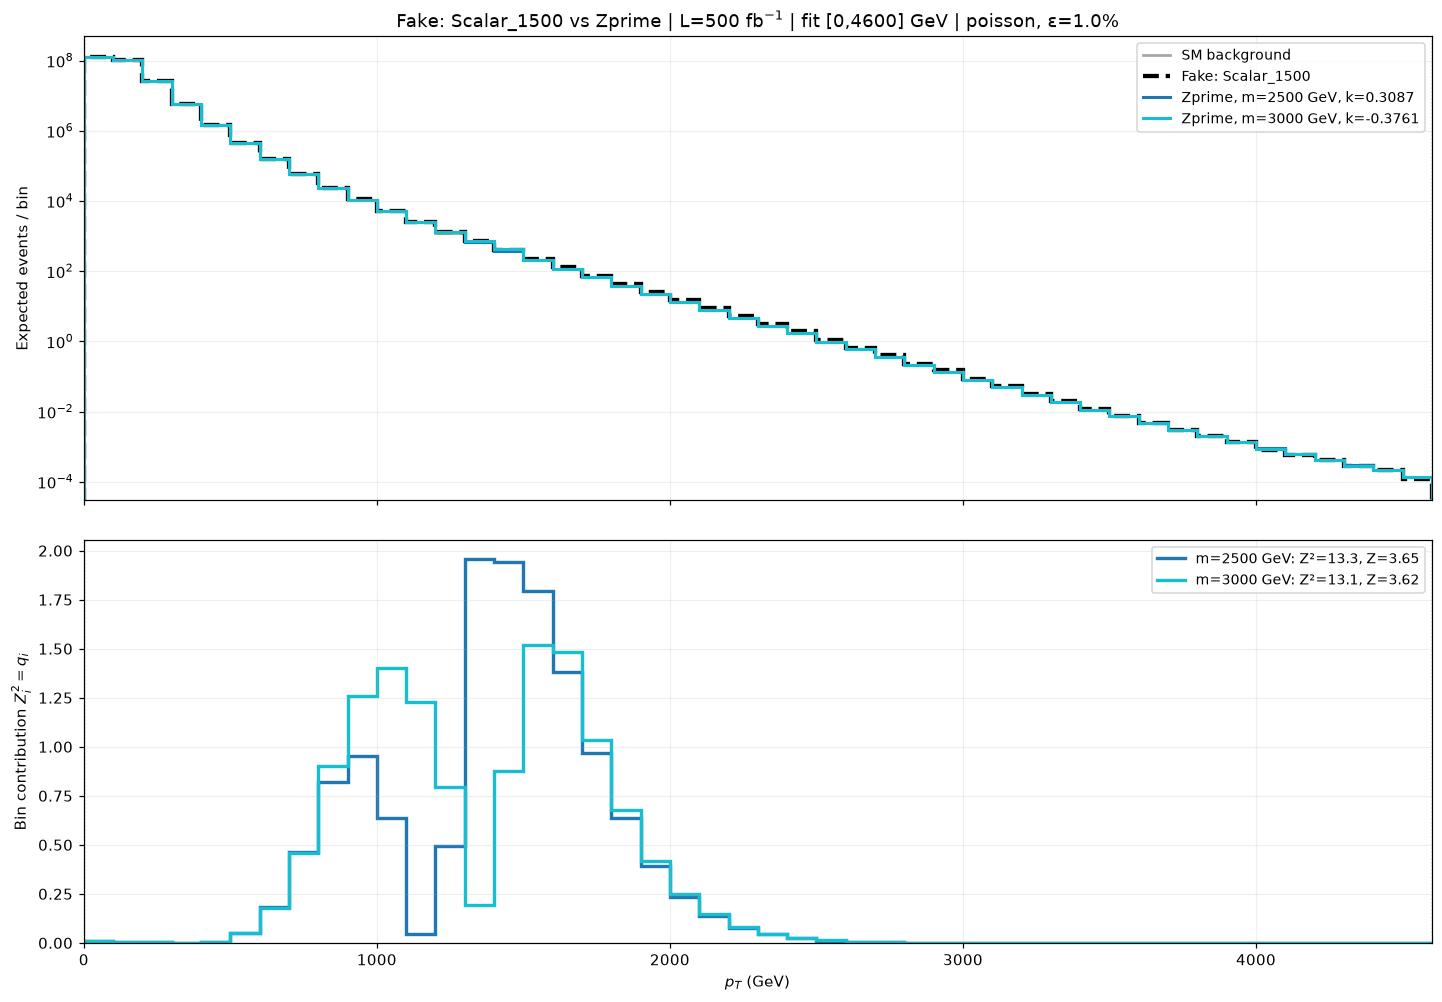

In [75]:
def draw_overlay(bins, plot_mask, fit_mask, n_sm, n_fake, fits, xlabel, statistic, epsilon, log_y=True):
    """Two panels: SM/fake/nominal best-fit counts and exactly additive per-bin q_i."""
    first = int(np.flatnonzero(plot_mask)[0]); last = int(np.flatnonzero(plot_mask)[-1]) + 1
    edges = bins[first:last+1]; sl = slice(first, last)
    fig, (ax, aq) = plt.subplots(2, 1, figsize=(13, 9), sharex=True,
                                 gridspec_kw={'height_ratios': [1.15, 1], 'hspace': 0.07},
                                 constrained_layout=True)
    ax.stairs(n_sm[sl], edges, color='0.65', lw=1.8, label='SM background')
    ax.stairs(n_fake[sl], edges, color='black', lw=2.8, linestyle='--', label=f'Fake: {FAKE_DATA_KEY}')
    colors = plt.cm.tab10(np.linspace(0, 0.9, max(len(fits), 2)))
    for color, result in zip(colors, fits):
        label = f'{TEST_MODEL}, m={result["mass"]:g} GeV, k={result["scale"]:.4g}'
        ax.stairs(result['n_test'][sl], edges, lw=2.0, color=color, label=label)
        aq.stairs(result['q_bins'][sl], edges, lw=2.2, color=color,
                  label=f'm={result["mass"]:g} GeV: Z²={result["Z2"]:.3g}, Z={result["Z"]:.3g}')
    for a in (ax, aq):
        a.axvline(FIT_RANGE[0], color='0.45', lw=0.9, ls=':')
        a.axvline(FIT_RANGE[1], color='0.45', lw=0.9, ls=':')
        a.set_xlim(edges[0], edges[-1])
    ax.set_ylabel('Expected events / bin')
    if log_y: ax.set_yscale('log')
    ax.legend(fontsize=9, loc='best', frameon=True)
    aq.set_ylabel(r'Bin contribution $Z_i^2 = q_i$')
    aq.set_xlabel(xlabel)
    aq.set_ylim(bottom=0)
    aq.legend(fontsize=9, loc='best')
    ax.set_title(f'Fake: {FAKE_DATA_KEY} vs {TEST_MODEL} | L={LUMINOSITY_FB:g} fb$^{{-1}}$ | '
                 f'fit [{FIT_RANGE[0]:g},{FIT_RANGE[1]:g}] GeV | {statistic}, ε={epsilon:.1%}')
    return fig

xlabel = (r'$p_T$ (GeV)' if OBSERVABLE in ('pT', 'pt_t') else
          r'$m_{t\bar t}$ (GeV)' if OBSERVABLE in ('m_tt', 'mTT') else f'{OBSERVABLE} (GeV)')
detail_systematics = systematics if PLOT_ALL_SYSTEMATICS else [selected_systematic]
fig_overlays = {}
for eps in detail_systematics:
    fig_overlays[eps] = draw_overlay(bins, plot_mask, fit_mask, n_sm, n_fake_total,
                                    fits_by_syst[eps], xlabel, STATISTIC, eps,
                                    log_y=(YIELD_Y_SCALE == 'log'))
    plt.show()


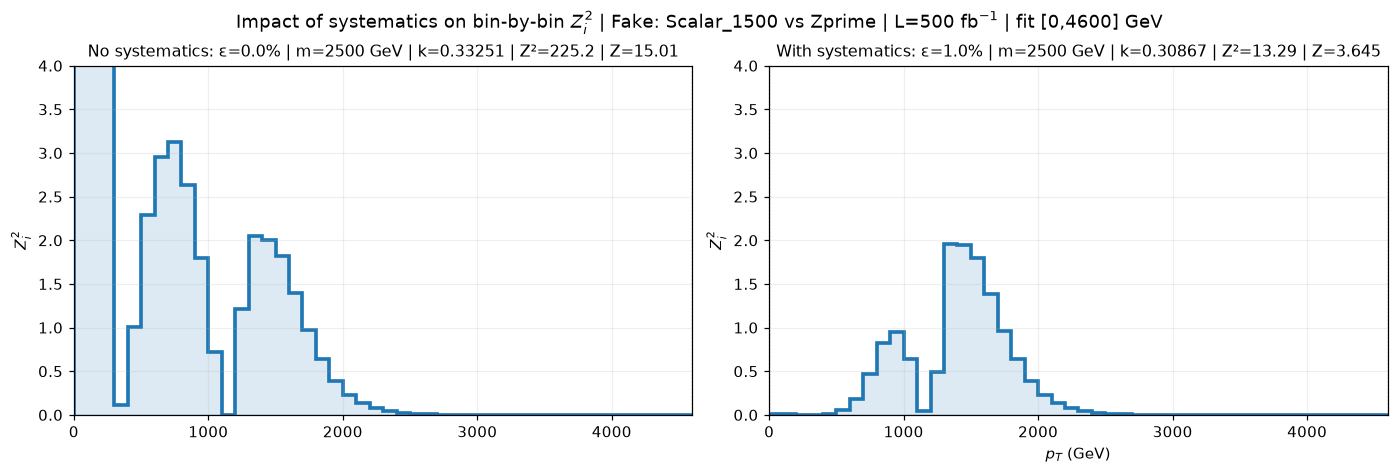

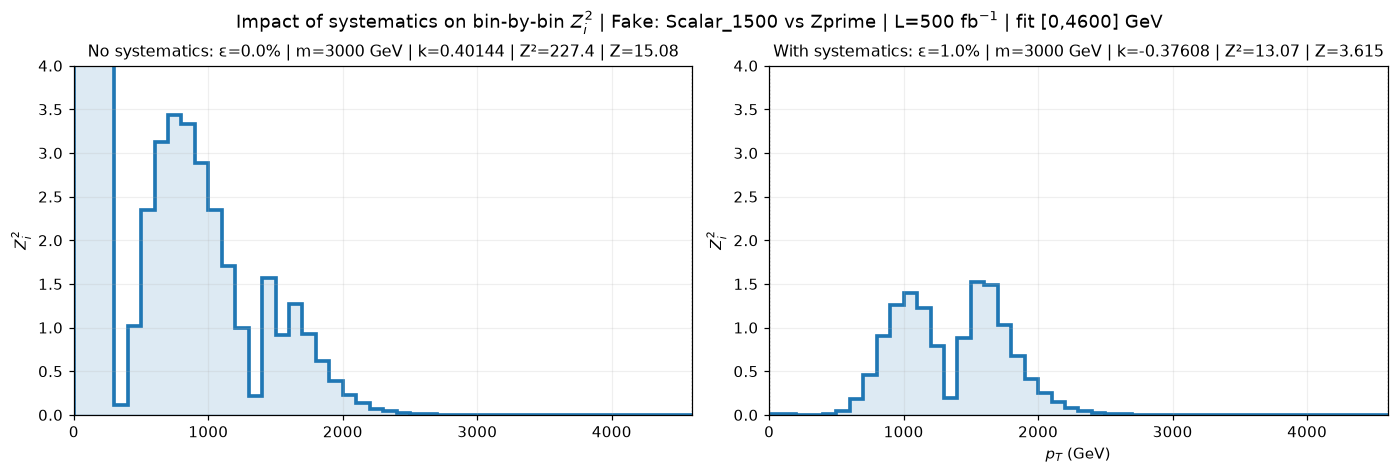

In [79]:
fig_pairwise_comparison = {}
if COMPARE_TO_NO_SYSTEMATICS:
    if not any(np.isclose(eps, 0.0, rtol=0.0, atol=1e-12) for eps in fits_by_syst):
        raise ValueError('A no-systematics result (epsilon=0) is required for direct comparison.')

    first = int(np.flatnonzero(plot_mask)[0])
    last = int(np.flatnonzero(plot_mask)[-1]) + 1
    edges = bins[first:last+1]
    sl = slice(first, last)

    def _result_for_mass(results, mass):
        for item in results:
            if np.isclose(float(item['mass']), float(mass), rtol=0.0, atol=1e-12):
                return item
        raise KeyError(f'No fit found for mass={mass:g} GeV.')

    baseline_eps = next(eps for eps in fits_by_syst if np.isclose(eps, 0.0, rtol=0.0, atol=1e-12))
    compare_eps = comparison_systematic
    paired_results = []
    for mass in sorted(test_templates):
        r0 = _result_for_mass(fits_by_syst[baseline_eps], mass)
        r1 = _result_for_mass(fits_by_syst[compare_eps], mass)
        paired_results.append((mass, r0, r1))

    for mass, r0, r1 in paired_results:
        if COMPARISON_LAYOUT == 'side_by_side':
            nrows, ncols = 1, 2
            figsize = (12.6, 4.2)
        else:
            nrows, ncols = 2, 1
            figsize = (9.0, 6.9)
        fig, axes = plt.subplots(nrows, ncols, figsize=figsize, sharex=False,
                                 constrained_layout=True)
        axes = np.atleast_1d(axes).ravel()
        panel_specs = [(baseline_eps, r0, 'No systematics'), (compare_eps, r1, 'With systematics')]
        ymax = max(np.nanmax(r0['q_bins'][sl]), np.nanmax(r1['q_bins'][sl]))
        ymax = 1.05 * ymax if np.isfinite(ymax) and ymax > 0 else 1.0
        for ax, (eps, result, title_prefix) in zip(axes, panel_specs):
            ax.stairs(result['q_bins'][sl], edges, lw=2.4, color='tab:blue')
            ax.fill_between(bins[:-1][sl], result['q_bins'][sl], step='post', alpha=0.15, color='tab:blue')
            ax.axvline(FIT_RANGE[0], color='0.45', lw=0.9, ls=':')
            ax.axvline(FIT_RANGE[1], color='0.45', lw=0.9, ls=':')
            ax.set_xlim(edges[0], edges[-1])
            ax.set_ylabel(r'$Z_i^2$')
            if COMPARISON_MATCH_YLIM:
                ax.set_ylim(0, 4.0)
            else:
                ax.set_ylim(bottom=0)
            ax.set_title(
                f'{title_prefix}: ε={eps:.1%} | m={mass:g} GeV | '
                f'k={result["scale"]:.5g} | Z²={result["Z2"]:.4g} | Z={result["Z"]:.4g}',
                fontsize=10.5
            )
        axes[-1].set_xlabel(xlabel)
        fig.suptitle(
            f'Impact of systematics on bin-by-bin $Z_i^2$ | Fake: {FAKE_DATA_KEY} vs {TEST_MODEL} '
            f'| L={LUMINOSITY_FB:g} fb$^{{-1}}$ | fit [{FIT_RANGE[0]:g},{FIT_RANGE[1]:g}] GeV',
            fontsize=12
        )
        fig_pairwise_comparison[mass] = fig
        plt.show()